# 01 · Dataset description and exploratory analysis

This notebook documents the Teva pharmaceutical sales dataset used in the INN/ATC cold-start study:
its structure, data quality, distributions, seasonality and the hierarchy of pharmaceutical attributes.
All numbers below are computed from the data when the notebook runs. The same tables and figures are written to
`results/tables/` and `results/figures/` by `python scripts/make_eda.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, Markdown, display

from teva_forecast import config, data, eda, plotting as P

pd.set_option("display.max_colwidth", 80)
P.apply_style()

## 1. Loading and validation

`prepare_data.py` downloads the raw CSV, verifies its SHA-256 checksum, validates the schema (10 attribute columns + 60 consecutive month columns, unique `Morion ID`) and writes the processed parquet files.

In [2]:
raw_path = data.download_raw("full")
attrs_raw, raw_sales, dates = data.load_wide(raw_path)
if not (config.PROCESSED_DIR / "teva_sku_attributes.parquet").exists():
    data.save_processed(data.build_dataset(attrs_raw, raw_sales, dates))
ds = data.load_processed("teva")
print(raw_path.name, attrs_raw.shape, raw_sales.shape, f"{dates[0]:%Y-%m}..{dates[-1]:%Y-%m}")
attrs_raw.head(3)

teva_sales.csv (13762, 10) (13762, 60) 2019-01..2023-12


,sku,atc1,atc2,atc3,atc4,atc5,brand,inn,nfc,description
0,111615,M MUSCULO-SCELETAL SYSTEM,M09 OTHER DRUGS FOR DISORDERS OF THE MUSCULO-SKELETAL SYSTEM,M09A OTHER DRUGS FOR DISORDERS OF THE MUSCULO-SKELETAL SYSTEM,M09A X Other drugs for disorders of the musculo-skeletal system,M09A X15** Other drugs,18968,-,Parenteral Ordinary,"sol. for inj. amp. 2 ml, #100"
1,102118,L ANTINEOPLASTIC AND IMMUNOMODULATING AGENTS,L01 ANTINEOPLASTIC AGENTS,L01E PROTEIN KINASE INHIBITORS,L01E X Other protein kinase inhibitors,L01E X02 Sorafenib,44664,SORAFENIBUM,Oral Solid Ordinary,"tabs coated w/film 200 mg, #112"
2,419910,L ANTINEOPLASTIC AND IMMUNOMODULATING AGENTS,L01 ANTINEOPLASTIC AGENTS,L01F MONOCLONAL ANTIBODIES AND ANTIBODY DRUG CONJUGATES,L01F F PD-1/PDL-1 (Programmed cell death protein 1/death ligand 1) inhibitors,L01F F02 Pembrolizumab,49990,PEMBROLIZUMABUM,Parenteral Ordinary,"conc. for infus. sol. 25 mg/ml flask 4 ml, #1"


## 2. Dataset characteristics

In [3]:
display(eda.dataset_characteristics(ds, (len(attrs_raw), pd.read_csv(raw_path, nrows=0).shape[1])))

,characteristic,value
0,Source file,teva_sales.csv (full dataset)
1,Raw shape (rows x columns),"13,762 x 70"
2,Unit of observation,SKU (Morion ID) x calendar month
3,Period,2019-01 to 2023-12 (60 months)
4,Target variable,"quantity sold, number of packs per SKU per month"
5,SKUs (Morion ID),"13,762"
6,INNs (active substances or combinations),"1,776"
7,ATC level 1 / 2 / 3 / 4 / 5 groups,"14 / 90 / 224 / 586 / 1,563"
8,Brands (anonymised codes),"4,895"
9,Dosage forms (NFC1),16


## 3. Pharmaceutical hierarchy: INN and ATC

All five ATC levels are filled for every SKU except 14 placeholder ATC4 codes, and ATC is a strict tree (no code has more than one parent). INN is a real value for 12,831 SKUs; 931 SKUs carry a placeholder ('-' after a non-breaking space) for products without an INN, which the pipeline treats as missing. ATC5 (chemical substance) is almost one-to-one with INN, while ATC1–ATC4 group several INNs together, which is what makes transfer to an unseen INN possible.

,level,groups,SKUs per group (median),SKUs per group (max),INNs per group (median),groups with >= 2 INNs,single-SKU groups
0,ATC1,14,886.0,2136,132.5,14,0
1,ATC2,90,100.0,982,16.0,84,2
2,ATC3,224,30.5,567,5.0,195,10
3,ATC4,586,10.0,229,2.0,381,62
4,ATC5,1563,3.0,187,1.0,155,384
5,INN,1776,3.0,167,1.0,0,514
6,Form (NFC),16,190.0,6245,39.0,16,0


,check,value
0,SKUs without an INN (placeholder '-' in the raw file),931.000
1,SKUs with a missing ATC4 code (placeholder '-'),14.000
2,INNs (excluding the placeholder),1776.000
3,ATC2 codes with more than one ATC1 parent,0.000
4,ATC3 codes with more than one ATC2 parent,0.000
5,ATC4 codes with more than one ATC3 parent,0.000
6,ATC5 codes with more than one ATC4 parent,0.000
7,ATC5 codes containing more than one INN,155.000
8,INNs appearing under more than one ATC5 code,188.000
9,INNs appearing under more than one ATC2 group,137.000


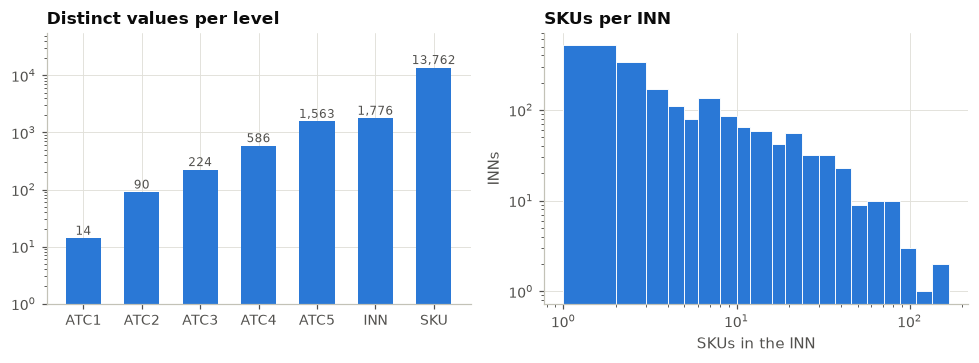

In [4]:
display(eda.hierarchy_table(ds))
display(eda.hierarchy_checks(ds))
fig = eda.fig_hierarchy(ds)

## 4. Data quality

No missing, negative or duplicated records were found. Zeros fall into three types with different meanings: before the first sale (the product is not on the market yet), gaps between the first and the last sale (no demand or a stock-out, which cannot be told apart without stock data), and zeros after the last sale (discontinued, or right-censored at 2023-12). Outlying months are flagged but kept: heavy tails are genuine for pharmacy sales.

In [5]:
display(eda.quality_report(ds, raw_sales))

,check,count,note
0,Missing attribute values in the raw file,0,but see the placeholders below
1,"Placeholder '-' in INN (product without an INN), treated as missing",931,
2,"Placeholder '-' in ATC4, treated as missing",14,
3,Missing monthly sales values,0,
4,Negative sales values,0,
5,Duplicate Morion IDs,0,
6,"SKUs with an identical twin (same ATC5, brand, INN, form, description)",1981,814 twin groups
7,SKUs without any sale in 60 months,0,
8,"Zero SKU-months, total",261130,31.6% of all cells
9,before the first sale (not yet on market),100675,12.2% of all cells


## 5. Product presentation parsed from `Description`

In [6]:
display(eda.parse_coverage(ds))
audit = eda.parsing_audit_sample(ds).merge(pd.read_csv(ROOT / "reports" / "description_parsing_audit.csv")[["sku", "manual_check"]], on="sku")
print(audit["manual_check"].value_counts().to_string())
audit[audit["manual_check"] != "correct"]

,field,share of SKUs
0,strength parsed,0.772925
1,of which mass per unit (mg),0.516567
2,"of which concentration (mg/ml, mg/g, %, IU/ml, ...)",0.235358
3,multiple strengths (combination product),0.038439
4,package content parsed (ml or g),0.404156
5,number of doses parsed,0.006830
6,pack count parsed (#N),0.882357


manual_check
correct                                        58
error: package mass (10 g) read as strength     1
error: package mass (40 g) read as strength     1


,sku,description,strength_value,strength_unit,multi_strength,content_value,content_unit,n_doses,pack_count,manual_check
44,19512,"gran. case 10 g, #1",10000.0,mg,0,NaN,none,NaN,1.0,error: package mass (10 g) read as strength
45,22971,collect. fruit 40 g pack,40000.0,mg,0,NaN,none,NaN,NaN,error: package mass (40 g) read as strength


## 6. Distribution of sales

,mean monthly packs per SKU
count,1.376200e+04
mean,6.251213e+03
std,2.941462e+04
min,3.225806e-04
10%,8.748365e-01
25%,3.878783e+01
50%,7.056292e+02
75%,4.088013e+03
90%,1.337293e+04
99%,8.555668e+04


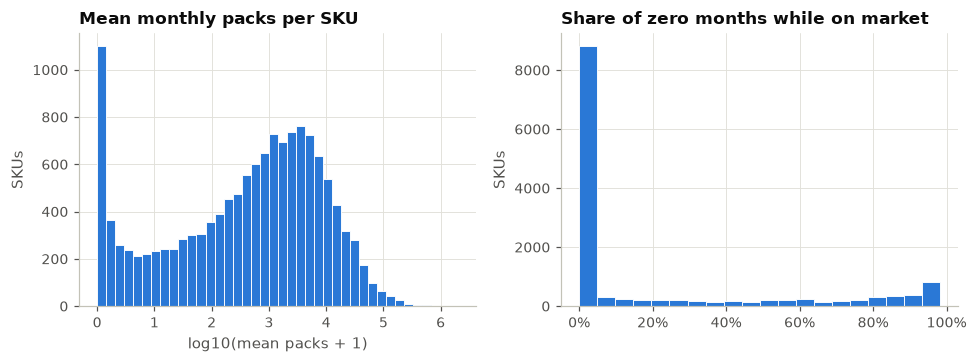

In [7]:
fig = eda.fig_sku_distribution(ds)
s = eda.sku_summary(ds)
s["mean_sales"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).to_frame("mean monthly packs per SKU")

In [8]:
top = s.sort_values("total_sales", ascending=False)["total_sales"]
print(f"top 1% of SKUs: {top.head(len(top) // 100).sum() / top.sum():.1%} of volume; "
      f"top 10%: {top.head(len(top) // 10).sum() / top.sum():.1%}")

top 1% of SKUs: 31.4% of volume; top 10%: 74.5%


## 7. Market dynamics over time

The total market has two sharp breaks: a spike and collapse in March–April 2020, and a collapse in March–April 2022 after which annual volume stays about 21% below 2021. The 2022 break falls inside the validation year, so validation errors are expected to be higher than test errors.

,million packs
2019,1107.3
2020,1062.9
2021,1068.1
2022,845.1
2023,848.8


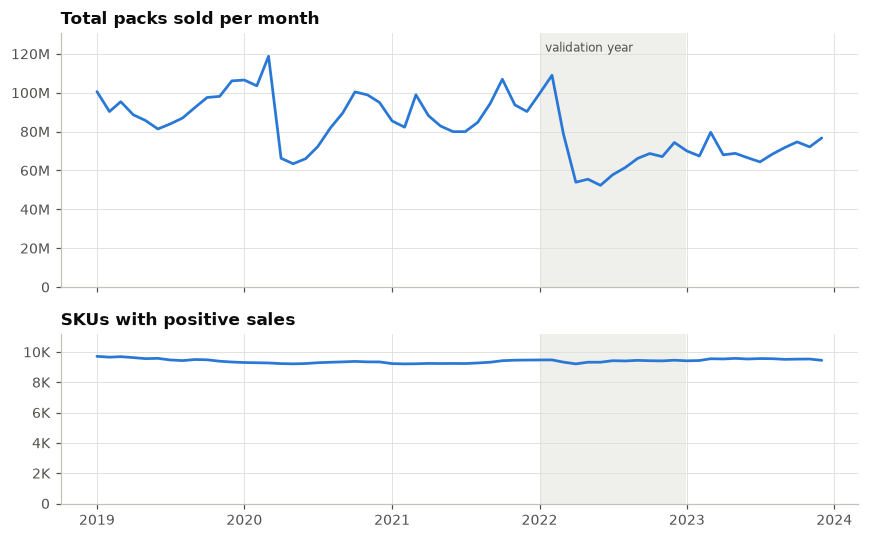

In [9]:
fig = eda.fig_monthly_total(ds)
annual = pd.Series(ds.sales0.sum(axis=0), index=ds.dates).groupby(ds.dates.year).sum()
(annual / 1e6).round(1).to_frame("million packs")

## 8. Groups of drugs

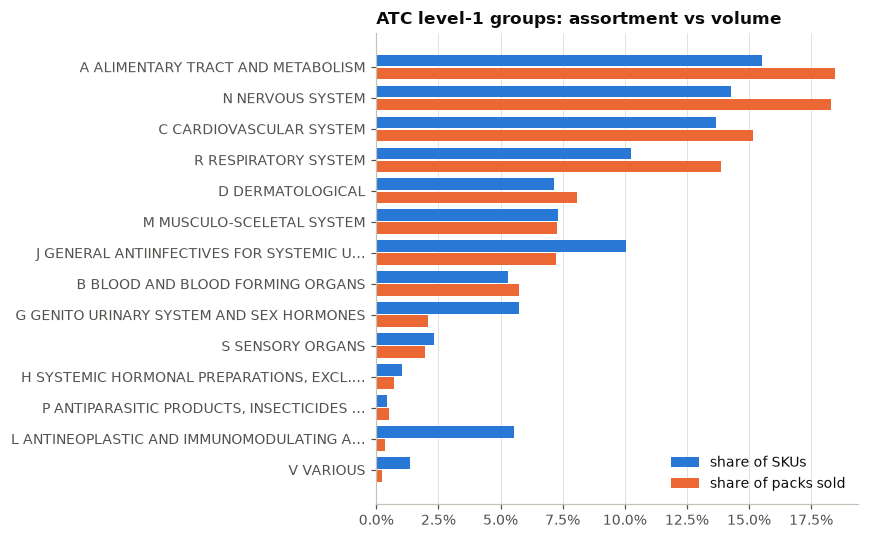

In [10]:
fig = eda.fig_atc1_composition(ds)

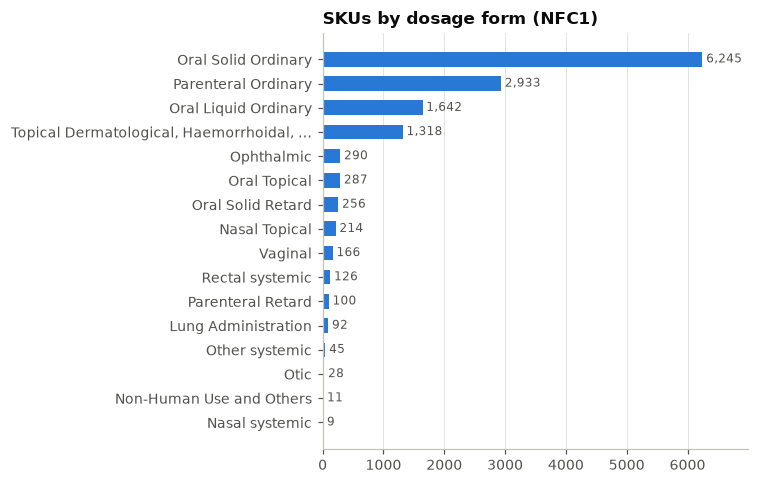

In [11]:
fig = eda.fig_forms(ds)

## 9. Seasonality

The index is each month's share of the annual total × 12, averaged over 2019–2023 (1 = average month). Anti-infectives (J), respiratory (R) and immunomodulators (L) show a strong winter peak and summer trough.

,lag-12 autocorrelation per SKU (>= 36 months on market)
count,10323.000000
mean,0.272906
std,0.336489
min,-0.882826
25%,0.007743
50%,0.270769
75%,0.545568
max,0.998020


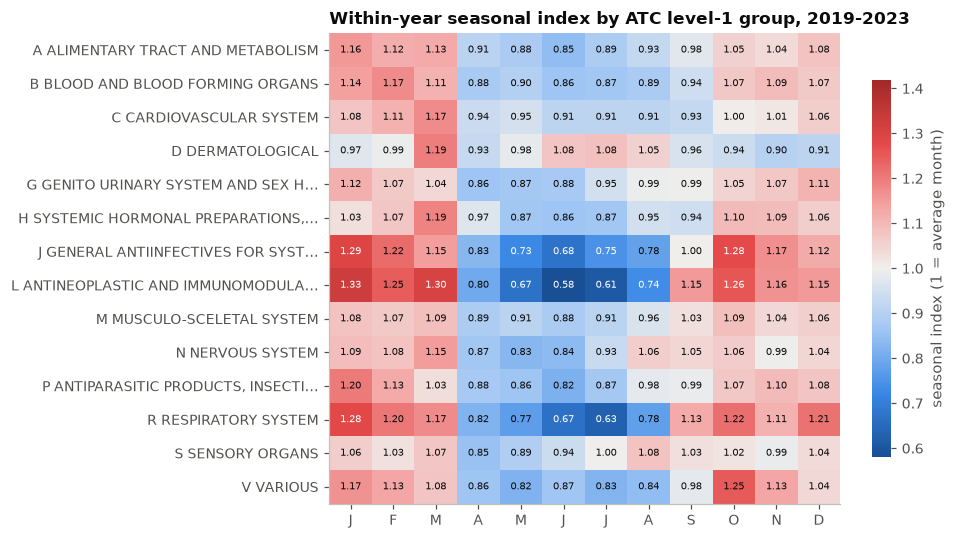

In [12]:
fig = eda.fig_seasonality(ds)
eda.lag12_autocorrelation(ds).describe().to_frame("lag-12 autocorrelation per SKU (>= 36 months on market)")

## 10. Product lifecycle and launches

Launches are observed through the first month with positive sales. SKUs already selling in 2019-01 are left-censored (their launch date is unknown). Entries in 2019 are inflated by sporadic SKUs whose January 2019 value happened to be zero.

,launch year,SKUs,INN sold before,new INN,no INN,with an older identical twin
0,2022,623,568,23,32,135
1,2023,617,555,20,42,124


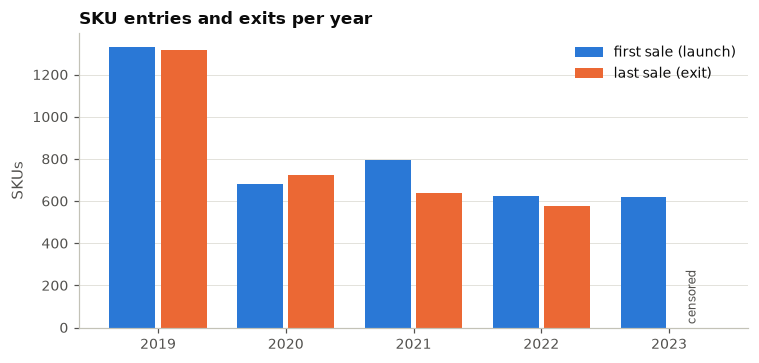

In [13]:
fig = eda.fig_lifecycle(ds)
eda.launch_composition(ds)

,month_since_launch,median,q25,q75
0,1,0.052,0.010,0.352
1,2,0.206,0.064,0.678
2,3,0.380,0.137,0.866
3,4,0.505,0.218,1.020
4,5,0.584,0.287,1.033
5,6,0.677,0.374,1.064
6,7,0.796,0.525,1.127
7,8,0.874,0.621,1.098
8,9,0.942,0.711,1.106
9,10,0.991,0.735,1.158


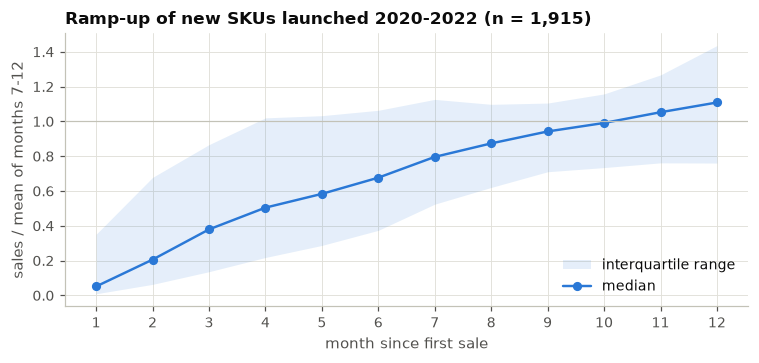

In [14]:
fig = eda.fig_launch_curve(ds)
curve, n = eda.launch_curve(ds)
curve.round(3)

## 11. How informative are INN and ATC about an unseen product?

For every SKU its log mean sales are predicted by the mean of the *other* SKUs in the same group (leave-one-out), and the R² over all SKUs is reported. Every grouping explains only a modest share of the between-SKU variance, because strength, pack size and brand drive the level strongly. ATC levels 3–4 are slightly more informative than INN alone, since they pool more peers.

,grouping,groups,SKUs with a peer in group,LOO R2 (log mean sales)
0,Form (NFC),16,1.000000,0.059172
1,ATC1,14,1.000000,0.102651
2,ATC2,90,0.999855,0.131233
3,ATC3,224,0.999273,0.150273
4,ATC4,586,0.994478,0.160218
5,ATC5,1563,0.972097,0.146520
6,INN,1776,0.895001,0.135212
7,INN x form,2299,0.880323,0.120448


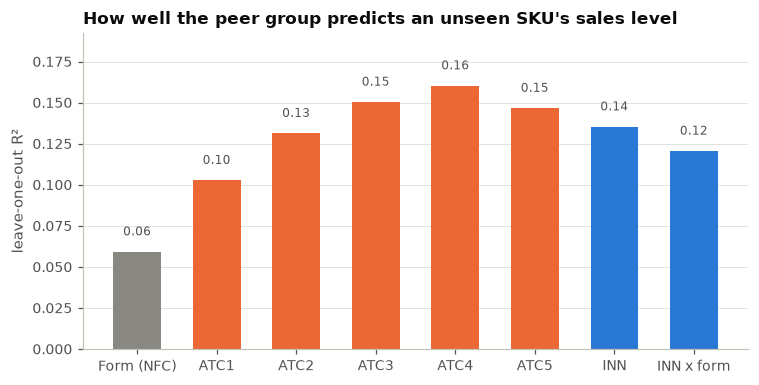

In [15]:
display(eda.group_informativeness(ds))
fig = eda.fig_group_informativeness(ds)